# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [26]:
ROLL_NO = 1024170106          # <-- your full roll number
NAME = "Swathi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [27]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [28]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [29]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170106   Name: Swathi   Fingerprint: A1BDE783   Tickets: 13

Ticket_ID                                                                        Ticket_Text
      T01           MATLAB was working yesterday on my laptop. It works on another computer.
      T02 Printer stopped responding after resetting my password. I don't know what changed.
      T03                                          The printer won't print; it isn't jammed.
      T04                                       Call me on +91 98765 43210 or 0175-239-3201.
      T05                                              I tried again... still no response!!!
      T06       Python failed to open when I use mobile hotspot. I have tried several times!
      T07                       Password was working yesterday on my laptop. This is urgent.
      T08    I can't open the Wi-Fi while uploading the file. The same problem occurs again.
      T09                                                     Error code 0x80070005 a

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [30]:
# Your code
# Q1: Preprocessing Pipeline

results = []
all_final_tokens = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    # Run the official preprocessing function
    p = process_ticket(text)

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation Tokens": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique Tokens": len(set(p["final"])),
        "Final Tokens": len(p["final"])
    })

    all_final_tokens.extend(p["final"])

# Create the table
q1_table = pd.DataFrame(results)

# Create TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation Tokens": q1_table["Punctuation Tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": len(set(all_final_tokens)),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

# Select ticket T01
selected_ticket = df[df["Ticket_ID"] == "T01"].iloc[0]

p = process_ticket(selected_ticket["Ticket_Text"])

print("Ticket ID:", selected_ticket["Ticket_ID"])
print("Ticket Text:", selected_ticket["Ticket_Text"])

print("\nTokens:")
print(p["tokens"])

print("\nPunctuation Tokens:")
print(p["punct"])

print("\nStopwords:")
print(p["stops"])

print("\nFinal Tokens:")
print(p["final"])

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,14,2,5,7,7
1,T02,2,15,2,5,8,8
2,T03,1,11,2,3,5,6
3,T04,1,9,1,3,5,5
4,T05,2,10,4,3,3,3
5,T06,2,16,2,5,9,9
6,T07,2,12,2,5,5,5
7,T08,2,17,2,7,8,8
8,T09,1,5,1,0,4,4
9,T10,2,10,2,4,4,4


Ticket ID: T01
Ticket Text: MATLAB was working yesterday on my laptop. It works on another computer.

Tokens:
['matlab', 'was', 'working', 'yesterday', 'on', 'my', 'laptop', '.', 'it', 'works', 'on', 'another', 'computer', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['was', 'on', 'my', 'it', 'on']

Final Tokens:
['matlab', 'working', 'yesterday', 'laptop', 'works', 'another', 'computer']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer: Some final tokens that are not complete words are `n't`, `ca`, and `wo`. They come from contractions such as “don't,” “can't,” and “won't.” During tokenization, these contractions are split into separate parts. Since the preprocessing pipeline removes stopwords but does not combine contraction fragments, these incomplete tokens remain in the final tokens.*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [31]:

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

def process_regex(text):

    # 1. Words longer than 5 letters
    long_words = re.findall(r'\b[A-Za-z]{6,}\b', text)

    # 2. All numbers, including decimals, versions and comma-separated numbers
    numbers = re.findall(
        r'\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)*',
        text
        )


    # 3. Capitalized words
    capitalized_words = re.findall(r'\b[A-Z][a-z]*\b', text)

    # 4. Words starting with a vowel
    vowel_words = re.findall(
        r"\b[AEIOUaeiou][A-Za-z]*\b",
        text
    )

    # 5. Mask email addresses
    masked_text = re.sub(
        r'\b[\w.-]+@[\w.-]+\.[A-Za-z]{2,}\b',
        '<EMAIL>',
        text
    )

    # 6. Mask URLs
    masked_text = re.sub(
        r'https?://[^\s]+|www\.[^\s]+',
        lambda m: '<URL>' + ('.' if m.group().endswith('.') else ''),
        masked_text
    )

    # 7. Mask phone numbers
    masked_text = re.sub(
        r'(?<!\w)(?:\+91[- ]?)?(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)',
        '<PHONE>',
        masked_text
    )

    return {
        "long_words": long_words,
        "numbers": numbers,
        "capitalized_words": capitalized_words,
        "vowel_words": vowel_words,
        "masked_text": masked_text
    }


# Test on TEST_LINES
for i, line in enumerate(TEST_LINES, start=1):
    result = process_regex(line)

    print(f"\n--- TEST LINE {i} ---")
    print("Original:", line)
    print("Words longer than 5 letters:", result["long_words"])
    print("Numbers:", result["numbers"])
    print("Capitalized words:", result["capitalized_words"])
    print("Words starting with a vowel:", result["vowel_words"])
    print("Masked text:", result["masked_text"])


# Apply to raw tickets if the dataframe exists
if "df" in globals() and "Ticket_Text" in df.columns:
    df["Regex_Results"] = df["Ticket_Text"].apply(process_regex)
    df["Masked_Text"] = df["Regex_Results"].apply(
        lambda x: x["masked_text"]
    )

    print("\n--- RAW TICKET RESULTS ---")
    print(df[["Ticket_Text", "Masked_Text"]].head())




--- TEST LINE 1 ---
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words starting with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Masked text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

--- TEST LINE 2 ---
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words longer than 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Capitalized words: ['Call', 'Version', 'Rs']
Words starting with a vowel: ['or', 'is']
Masked text: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

--- TEST LINE 3 ---
Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words longer than 5 letters: []

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer: Some of the capitalized words are capitalized only because they appear at the beginning of a sentence, such as “Printer,” “The,” “I,” and “Password.” Therefore, not all capitalized words represent proper nouns; some are capitalized due to normal sentence-writing rules.*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [32]:
# Your code

import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Custom tokenizer: preserve URLs, emails, phone numbers,
# versions, decimals, contractions and hyphenated words


pattern = (
    r'https?://[^\s]+|www\.[^\s]+'
    r'|[\w.-]+@[\w.-]+\.[A-Za-z]{2,}'
    r'|0[xX][0-9A-Fa-f]+'
    r'|\+?\d[\d\s().-]*\d'
    r'|\d+(?:\.\d+)+'
    r"|[A-Za-z]+(?:[-'][A-Za-z]+)*"
    r'|\d+'
)

custom_tokenizer = RegexpTokenizer(pattern)


# Test on TEST_LINES
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\n--- TEST LINE {i} ---")
    print("Original:", line)
    print("Custom tokens:", custom_tokenizer.tokenize(line))
    print("word_tokenize:", word_tokenize(line))


# Apply to raw tickets
if "df" in globals() and "Ticket_Text" in df.columns:
    for index, row in df.iterrows():
        text = row["Ticket_Text"]

        print(f"\n--- Ticket {row.get('Ticket_ID', index)} ---")
        print("Original:", text)
        print("Custom tokens:", custom_tokenizer.tokenize(text))
        print("word_tokenize:", word_tokenize(text))



--- TEST LINE 1 ---
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- TEST LINE 2 ---
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

--- TEST LINE 3 ---
Original: The state-of-the-art lab isn't open

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer: All 13 tickets are tokenized differently by `my_tokenize` and `word_tokenize`. The differences mainly involve punctuation, contractions, and how certain words are split or grouped.*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [33]:
# Your code

import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer

# Download the required NLTK resources
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Use your unique final tokens from Q1
words = list(dict.fromkeys(all_final_tokens))

# Initialize the four methods
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix rule based on words in the tickets:
# ing: working, responding, running
# ed: stopped, failed
# ly: slowly
regexp_stemmer = RegexpStemmer(r'ing$|ed$|ly$', min=4)

lemmatizer = WordNetLemmatizer()

# Convert nltk.pos_tag tags into WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'  # Adjective
    elif tag.startswith('V'):
        return 'v'  # Verb
    elif tag.startswith('N'):
        return 'n'  # Noun
    elif tag.startswith('R'):
        return 'r'  # Adverb
    else:
        return 'n'  # Default: noun

# Get POS tags
pos_tags = nltk.pos_tag(words)

# Compare the outputs
results = []

for word, tag in pos_tags:
    word_lower = word.lower()
    wn_pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word_lower)
    lancaster_result = lancaster.stem(word_lower)
    regexp_result = regexp_stemmer.stem(word_lower)
    lemma_result = lemmatizer.lemmatize(word_lower, pos=wn_pos)

    # Keep only words where at least two methods differ
    if len(set([
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ])) > 1:
        results.append({
            'Word': word,
            'POS Tag': tag,
            'Porter': porter_result,
            'Lancaster': lancaster_result,
            'Regexp': regexp_result,
            'WordNet Lemma': lemma_result
        })

comparison_df = pd.DataFrame(results)

print("Words where the outputs differ:")
display(comparison_df)


[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Words where the outputs differ:


,Word,POS Tag,Porter,Lancaster,Regexp,WordNet Lemma
0,works,VBZ,work,work,works,work
1,another,DT,anoth,anoth,another,another
2,computer,NN,comput,comput,computer,computer
3,printer,NN,printer,print,printer,printer
4,stopped,VBD,stop,stop,stopp,stop
5,resetting,VBG,reset,reset,resett,reset
6,changed,VBN,chang,chang,chang,change
7,jammed,JJ,jam,jam,jamm,jammed
8,call,NN,call,cal,call,call
9,tried,VBD,tri,tri,tri,try


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer: **Over-stemming:** The word “computer” becomes “comput” with PorterStemmer, which is not a complete English word.

**Under-stemming:** The word “jammed” remains “jammed” with WordNetLemmatizer, instead of reducing it to “jam,” because it was tagged as an adjective.*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus Statistics:


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,162,84,0.5185
1,S2 - No punctuation,136,79,0.5809
2,S3 - Final tokens,78,56,0.7179
3,S4 - Porter stemmed,78,54,0.6923


Top 10 words in S1:


,Word,Frequency
0,.,18
1,the,10
2,i,7
3,n't,6
4,password,5
5,is,5
6,on,4
7,!,4
8,this,4
9,yesterday,3


Top 10 words in S3:


,Word,Frequency
0,n't,6
1,password,5
2,yesterday,3
3,open,3
4,working,2
5,laptop,2
6,printer,2
7,tried,2
8,urgent,2
9,ca,2


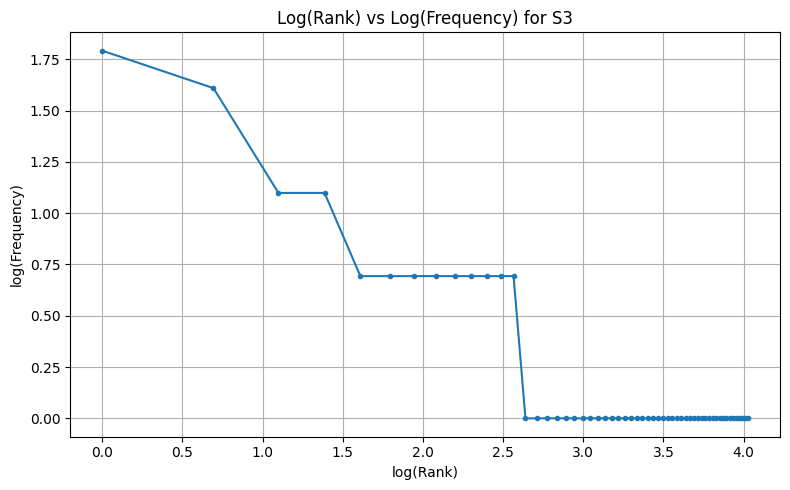

Top 5 bigrams in S1:


,Bigram,Frequency
0,the password,3
1,was working,2
2,working yesterday,2
3,yesterday on,2
4,on my,2


Top 5 bigrams in S3:


,Bigram,Frequency
0,working yesterday,2
1,yesterday laptop,2
2,ca n't,2
3,n't open,2
4,password running,2


In [34]:
# Your code

# Q5: Corpus Statistics

import pandas as pd
import matplotlib.pyplot as plt
import math

from collections import Counter
from nltk.stem import PorterStemmer

porter = PorterStemmer()

# Store tokens for all four corpus versions
S1 = []  # All tokens, including punctuation
S2 = []  # Tokens without punctuation
S3 = []  # Final tokens after preprocessing
S4 = []  # S3 after Porter stemming

# Keep each ticket separate for calculating bigrams
S1_by_ticket = []
S3_by_ticket = []

for _, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])

    # S1: All tokens
    tokens = p["tokens"]
    S1.extend(tokens)
    S1_by_ticket.append(tokens)

    # S2: Remove punctuation tokens
    punctuation = set(p["punct"])
    no_punctuation = [word for word in tokens
                      if word not in punctuation]
    S2.extend(no_punctuation)

    # S3: Final tokens
    final_tokens = p["final"]
    S3.extend(final_tokens)
    S3_by_ticket.append(final_tokens)

# S4: Apply Porter stemming to S3
S4 = [porter.stem(word.lower()) for word in S3]


# 1. Token count, unique tokens and TTR
def corpus_stats(name, corpus):
    total_tokens = len(corpus)
    unique_tokens = len(set(corpus))
    ttr = unique_tokens / total_tokens if total_tokens > 0 else 0

    return {
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame([
    corpus_stats("S1 - All tokens", S1),
    corpus_stats("S2 - No punctuation", S2),
    corpus_stats("S3 - Final tokens", S3),
    corpus_stats("S4 - Porter stemmed", S4)
])

print("Corpus Statistics:")
display(stats)


# 2. Top 10 words in S1 and S3
print("Top 10 words in S1:")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("Top 10 words in S3:")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))


# 3. Plot log(rank) vs log(frequency) for S3
frequency_counts = Counter(S3)
sorted_frequencies = sorted(
    frequency_counts.values(), reverse=True
)

ranks = list(range(1, len(sorted_frequencies) + 1))
log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [
    math.log(freq) for freq in sorted_frequencies
]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker='o',
         markersize=3, linestyle='-')

plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()


# 4. Top 5 bigrams in S1 and S3
# Calculate bigrams separately for each ticket so that
# the last word of one ticket isn't paired with the next ticket.

def get_bigram_counts(ticket_lists):
    bigrams = []

    for tokens in ticket_lists:
        bigrams.extend(zip(tokens, tokens[1:]))

    return Counter(bigrams)

S1_bigrams = get_bigram_counts(S1_by_ticket)
S3_bigrams = get_bigram_counts(S3_by_ticket)

print("Top 5 bigrams in S1:")
display(pd.DataFrame([
    {"Bigram": f"{a} {b}", "Frequency": count}
    for (a, b), count in S1_bigrams.most_common(5)
]))

print("Top 5 bigrams in S3:")
display(pd.DataFrame([
    {"Bigram": f"{a} {b}", "Frequency": count}
    for (a, b), count in S3_bigrams.most_common(5)
]))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer: TTR increases from 0.5185 in S1 to 0.6923 in S4 because S1 includes all tokens, including punctuation and common words, while S4 contains cleaned and stemmed tokens. Preprocessing removes punctuation, stopwords, and other tokens, reducing the total number of tokens. Stemming also combines different word forms into common stems, reducing the number of unique tokens. These changes affect the ratio of unique tokens to total tokens.*